# VisionInspect AI – Stage 1: Image Processing + Anomaly Detection
MVTec AD (cable) · Image → Preprocessing → ResNet50 features → Anomaly score → Normal/Anomaly

## 1. Setup

In [1]:
!pip -q install huggingface_hub

In [2]:
import os, json, random
import numpy as np
import pandas as pd
import cv2
import torch, torch.nn as nn
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import HfApi, hf_hub_download
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## 2. Config

In [3]:
REPO_ID = "chooseanything/mvtec-ad-cable"   # MVTec AD, cable category (Hugging Face)
CATEGORY = "cable"
N_TRAIN = 100            # defect-free training images
N_TEST_GOOD = 30         # defect-free test images
N_TEST_PER_DEFECT = 10   # test images per defect type
IMG_SIZE = 224           # ResNet50 input size
BATCH = 16
K = 3                    # nearest neighbours for the anomaly score
USE_DENOISE = True
USE_CLAHE = True         # contrast enhancement
ARTIFACT_DIR = "artifacts"

## 3. Load MVTec AD (remote, selected images only)

In [4]:
files = HfApi().list_repo_files(REPO_ID, repo_type="dataset")
imgs = [f for f in files if f.lower().endswith((".png", ".jpg", ".jpeg")) and "ground_truth" not in f]

def split_of(f):
    parts = f.split("/")
    return "train" if "train" in parts else ("test" if "test" in parts else None)

train_all = sorted(f for f in imgs if split_of(f) == "train" and f.split("/")[-2] == "good")
test_all  = sorted(f for f in imgs if split_of(f) == "test")
print("train (good):", len(train_all), "| test:", len(test_all))
assert len(train_all) > 0 and len(test_all) > 0, "No images found - check repo structure"

# small subset so the notebook runs fast
train_files = random.sample(train_all, min(N_TRAIN, len(train_all)))
test_good = [f for f in test_all if f.split("/")[-2] == "good"]
test_files = random.sample(test_good, min(N_TEST_GOOD, len(test_good)))
defect_types = sorted({f.split("/")[-2] for f in test_all} - {"good"})
for d in defect_types:
    fs = [f for f in test_all if f.split("/")[-2] == d]
    test_files += random.sample(fs, min(N_TEST_PER_DEFECT, len(fs)))

# MVTec ground truth: test/good = normal (0), test/<defect> = anomaly (1)
test_types  = [f.split("/")[-2] for f in test_files]
test_labels = np.array([0 if t == "good" else 1 for t in test_types])
print("defect types:", defect_types)
print("using", len(train_files), "train /", len(test_files), "test images")

train (good): 224 | test: 150
defect types: ['bent_wire', 'cable_swap', 'combined', 'cut_inner_insulation', 'cut_outer_insulation', 'missing_cable', 'missing_wire', 'poke_insulation']
using 100 train / 110 test images


In [5]:
def fetch(f):
    return hf_hub_download(REPO_ID, f, repo_type="dataset")

with ThreadPoolExecutor(8) as ex:
    train_paths = list(ex.map(fetch, train_files))
    test_paths  = list(ex.map(fetch, test_files))
print("downloaded:", len(train_paths) + len(test_paths))

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


cable/train/good/006.png: reconstructing file:   0%|          |  0.00B / 1.34MB            

cable/train/good/062.png: reconstructing file:   0%|          |  0.00B / 1.35MB            

cable/train/good/189.png: reconstructing file:   0%|          |  0.00B / 1.35MB            

cable/train/good/028.png: reconstructing file:   0%|          |  0.00B / 1.38MB            

cable/train/good/035.png: reconstructing file:   0%|          |  0.00B / 1.36MB            

... (411 outputs left out)

cable/test/poke_insulation/002.png: downloading bytes:           |  0.00B            

cable/test/poke_insulation/008.png: reconstructing file:   0%|          |  0.00B / 1.33MB            

cable/test/poke_insulation/008.png: downloading bytes:           |  0.00B            

downloaded: 210


## 4. Image preprocessing

In [6]:
def denoise(arr):
    return cv2.fastNlMeansDenoisingColored(arr, None, 3, 3, 7, 21)

def enhance(arr):   # CLAHE on the lightness channel
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

to_tensor = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),   # ImageNet stats
])

def preprocess(img):
    arr = np.array(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    if USE_DENOISE: arr = denoise(arr)
    if USE_CLAHE:   arr = enhance(arr)
    return Image.fromarray(arr)

class ImgDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return to_tensor(preprocess(Image.open(self.paths[i])))

Original  : (1024, 1024) mode RGB
RGB       : (1024, 1024) mode RGB
Resized   : (224, 224, 3)
Tensor    : (3, 224, 224) | mean 0.09, std 1.08


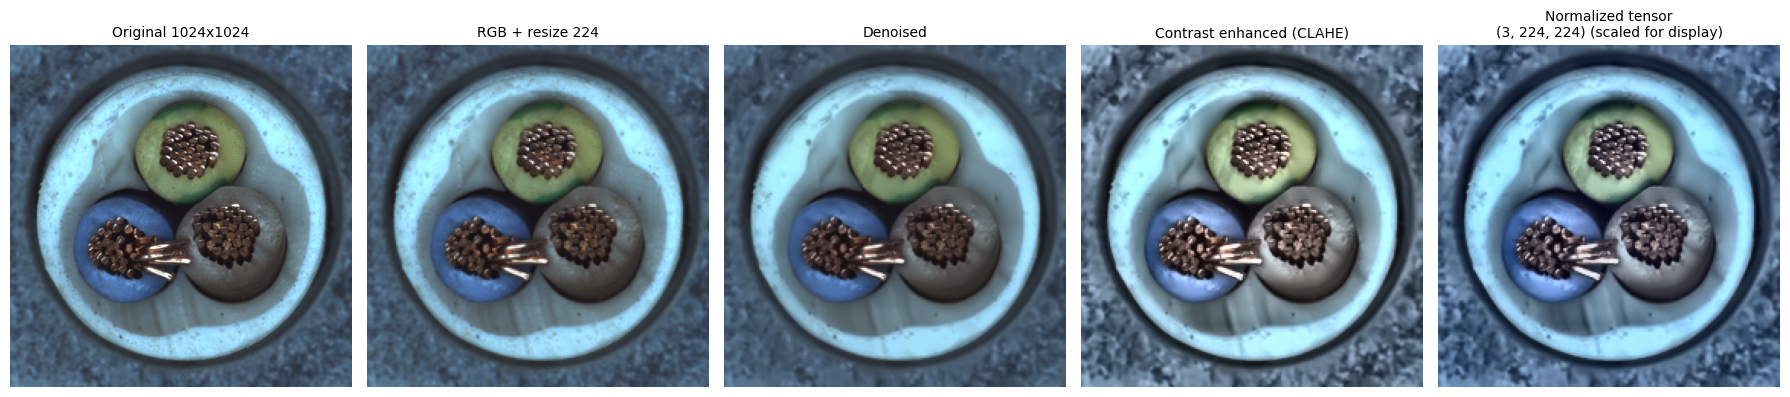

In [7]:
# Sample image: before / after each step
i = int(np.where(test_labels == 1)[0][0])
orig = Image.open(test_paths[i])
rgb = orig.convert("RGB")
resized = np.array(rgb.resize((IMG_SIZE, IMG_SIZE)))
denoised = denoise(resized)
enhanced = enhance(denoised)
tensor = to_tensor(Image.fromarray(enhanced))

print("Original  :", orig.size, "mode", orig.mode)
print("RGB       :", rgb.size, "mode", rgb.mode)
print("Resized   :", resized.shape)
print("Tensor    :", tuple(tensor.shape), "| mean %.2f, std %.2f" % (tensor.mean(), tensor.std()))

t_vis = tensor.permute(1, 2, 0).numpy()
t_vis = (t_vis - t_vis.min()) / (t_vis.max() - t_vis.min())
steps = [(orig, "Original %dx%d" % orig.size), (rgb.resize((IMG_SIZE, IMG_SIZE)), "RGB + resize %d" % IMG_SIZE),
         (denoised, "Denoised"), (enhanced, "Contrast enhanced (CLAHE)"),
         (t_vis, "Normalized tensor\n%s (scaled for display)" % (tuple(tensor.shape),))]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (im, title) in zip(axes, steps):
    ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. ResNet50 feature extraction + anomaly detection

In [8]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Identity()          # 2048-d features, no classification head
model.eval().to(device)

@torch.no_grad()
def extract(paths):
    loader = DataLoader(ImgDS(paths), batch_size=BATCH)
    return np.concatenate([model(b.to(device)).cpu().numpy() for b in loader])

train_feats = extract(train_paths)
test_feats  = extract(test_paths)
print(train_feats.shape, test_feats.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 111MB/s]


(100, 2048) (110, 2048)


In [9]:
# Normal feature representation (defect-free images only)
idx = np.random.permutation(len(train_feats))
n_val = len(idx) // 5
bank      = train_feats[idx[n_val:]]    # normal reference features
val_feats = train_feats[idx[:n_val]]    # held-out normal images (for threshold)

nn_model = NearestNeighbors(n_neighbors=K).fit(bank)

def anomaly_score(feats):
    d, _ = nn_model.kneighbors(feats)
    return d.mean(axis=1)               # mean distance to K nearest normal features

val_scores  = anomaly_score(val_feats)
test_scores = anomaly_score(test_feats)

threshold = float(np.percentile(val_scores, 95))   # from normal images only
test_pred = (test_scores > threshold).astype(int)  # 0 = Normal, 1 = Anomaly

print("reference:", bank.shape, "| held-out normal:", val_feats.shape)
print("threshold: %.3f" % threshold)
print("mean score - normal: %.2f | anomaly: %.2f" %
      (test_scores[test_labels == 0].mean(), test_scores[test_labels == 1].mean()))

reference: (80, 2048) | held-out normal: (20, 2048)
threshold: 6.235
mean score - normal: 6.02 | anomaly: 7.11


Current stage: Image preprocessing, feature extraction and anomaly detection. Defect-type classification and severity assessment are planned as later stages.

## 6. Evaluation

ResNet50 is being used as a feature extractor for anomaly detection. The evaluation measures how effectively the resulting anomaly scores separate normal and anomalous samples.

In [10]:
metrics = {
    "Accuracy":  accuracy_score(test_labels, test_pred),
    "Precision": precision_score(test_labels, test_pred, zero_division=0),
    "Recall":    recall_score(test_labels, test_pred, zero_division=0),
    "F1-score":  f1_score(test_labels, test_pred, zero_division=0),
    "ROC-AUC":   roc_auc_score(test_labels, test_scores),
}
metrics = {k: float(v) for k, v in metrics.items()}
pd.Series(metrics).round(3).to_frame("value")

,value
Accuracy,0.645
Precision,0.806
Recall,0.675
F1-score,0.735
ROC-AUC,0.755


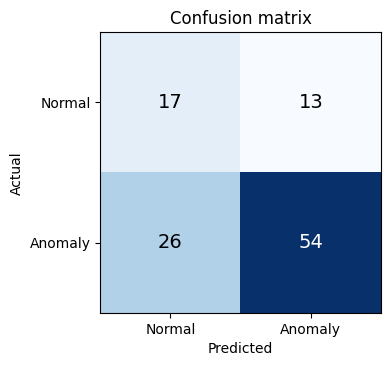

In [11]:
cm = confusion_matrix(test_labels, test_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
for r in range(2):
    for c in range(2):
        ax.text(c, r, cm[r, c], ha="center", va="center", fontsize=14,
                color="white" if cm[r, c] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Anomaly"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Anomaly"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix")
plt.tight_layout(); plt.show()

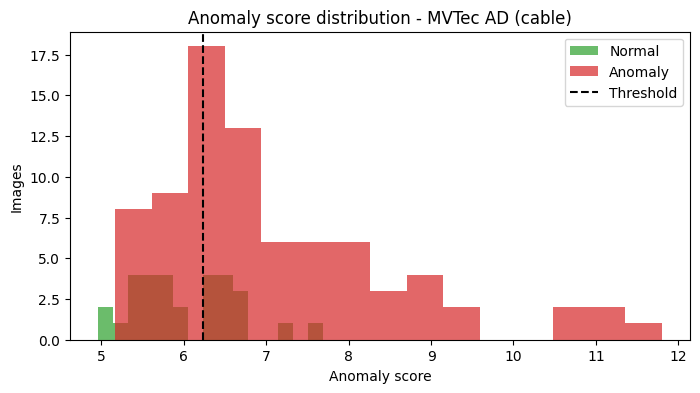

,count,mean score
type,,
bent_wire,10,7.63
cable_swap,10,6.31
combined,10,7.78
cut_inner_insulation,10,6.44
cut_outer_insulation,10,6.58
good,30,6.02
missing_cable,10,8.74
missing_wire,10,7.14
poke_insulation,10,6.25


In [12]:
plt.figure(figsize=(8, 4))
plt.hist(test_scores[test_labels == 0], bins=15, alpha=0.7, label="Normal", color="tab:green")
plt.hist(test_scores[test_labels == 1], bins=15, alpha=0.7, label="Anomaly", color="tab:red")
plt.axvline(threshold, color="black", linestyle="--", label="Threshold")
plt.xlabel("Anomaly score"); plt.ylabel("Images"); plt.legend()
plt.title("Anomaly score distribution - MVTec AD (%s)" % CATEGORY)
plt.show()

pd.DataFrame({"type": test_types, "score": test_scores}).groupby("type")["score"] \
  .agg(["count", "mean"]).round(2).rename(columns={"mean": "mean score"})

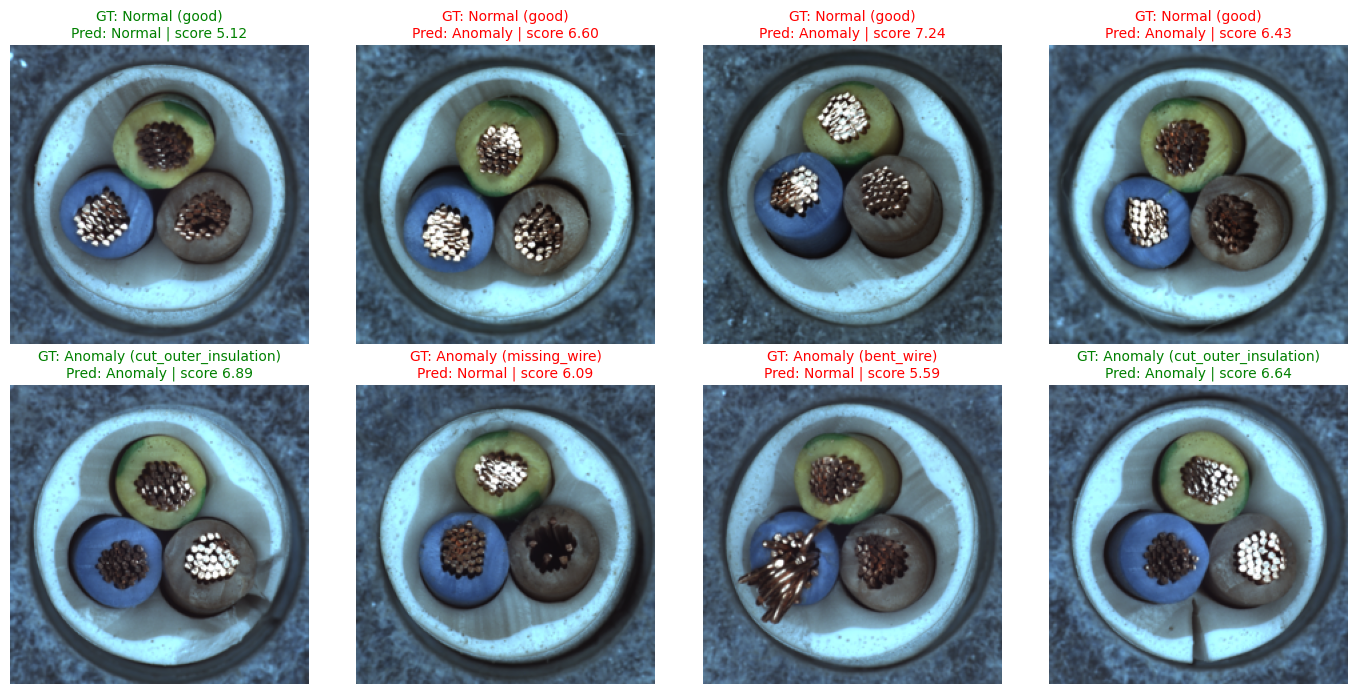

In [13]:
# Example predictions: ground truth vs predicted
names = {0: "Normal", 1: "Anomaly"}
rng = np.random.RandomState(SEED)
pick = list(rng.choice(np.where(test_labels == 0)[0], 4, replace=False)) + \
       list(rng.choice(np.where(test_labels == 1)[0], 4, replace=False))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(Image.open(test_paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    ok = test_pred[i] == test_labels[i]
    ax.set_title("GT: %s (%s)\nPred: %s | score %.2f" %
                 (names[test_labels[i]], test_types[i], names[test_pred[i]], test_scores[i]),
                 color="green" if ok else "red", fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Save artifacts

In [14]:
os.makedirs(ARTIFACT_DIR, exist_ok=True)
np.save(f"{ARTIFACT_DIR}/normal_features.npy", bank)
with open(f"{ARTIFACT_DIR}/config.json", "w") as f:
    json.dump({
        "category": CATEGORY, "backbone": "resnet50_imagenet", "feature_dim": int(bank.shape[1]),
        "img_size": IMG_SIZE, "k_neighbors": K, "denoise": USE_DENOISE, "clahe": USE_CLAHE,
        "threshold": threshold, "metrics": metrics,
    }, f, indent=2)
print(os.listdir(ARTIFACT_DIR))

['config.json', 'normal_features.npy']
